# Module 05, Part 1: Attention as a learned lookup

This notebook is the runnable companion to Part 1 of the Module 05 learning
content. It checks, with code:

1. A soft lookup returns a similarity-weighted blend of values, and a hard
   lookup is its limiting case.
2. Scaled dot-product attention written by hand matches PyTorch's own
   implementation, including the causal mask.
3. The $\sqrt{d_k}$ in the formula is not decoration: without it the softmax
   saturates as the key dimension grows, and its gradient disappears.
4. Distance stops mattering. The delayed-recall task from Module 04, where an
   open-gate LSTM stayed at chance at 200 steps, is solved at every length we
   try by a single attention read.

Everything runs on CPU in a few minutes.

In [1]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.10.0+cpu


## 1. A lookup table, then a soft one

A Python dictionary does a **hard** lookup: the query must equal a key exactly,
and you get back one value. Attention keeps the idea (a query, some keys, some
values) but replaces "equal" with "similar" and "one value" with "a blend".

Below, the keys are three points on a line. The query sits between the first
two. A hard lookup returns the value of the nearest key. A soft lookup weighs
every value by how close its key is to the query.

In [2]:
keys = torch.tensor([0.0, 1.0, 5.0])
values = torch.tensor([10.0, 20.0, 90.0])
query = torch.tensor(0.4)

hard = values[(keys - query).abs().argmin()]
similarity = -(keys - query).pow(2)                 # closer key, higher score
weights = torch.softmax(similarity, dim=0)          # scores to weights that sum to 1
soft = (weights * values).sum()

print("hard lookup returns:", hard.item())
print("soft weights:       ", [round(w, 3) for w in weights.tolist()], " sum =", round(weights.sum().item(), 3))
print("soft lookup returns:", round(soft.item(), 2))

hard lookup returns: 10.0
soft weights:        [0.55, 0.45, 0.0]  sum = 1.0
soft lookup returns: 14.5


The soft lookup lands between the two nearby values and ignores the far one.
Because the weights come from a softmax, the whole thing is differentiable: the
network can learn which keys a query should match, and what values to store.

## 2. Scaled dot-product attention, from scratch

In attention the similarity is a **dot product** between a query vector and each
key vector, and the blend is taken over **value** vectors:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^{\top}}{\sqrt{d_k}}\right) V$$

Here is the whole thing, written with plain tensor operations.

In [3]:
def causal_mask(length):
    """Boolean mask of shape (length, length). True means 'this position may be attended to'.
    Row i (the query) may look at columns 0..i (the keys), never at the future."""
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def scaled_dot_product_attention(q, k, v, mask=None, scale=True):
    """softmax(q k^T / sqrt(d_k)) v.

    q: (..., T_q, d_k)   k: (..., T_k, d_k)   v: (..., T_k, d_v)
    mask: boolean, broadcastable to (..., T_q, T_k); False entries are blocked.
    Returns (output, weights). Set scale=False to see why the scaling matters.
    """
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1)
    if scale:
        scores = scores / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights

In [4]:
torch.manual_seed(0)
q = torch.randn(2, 5, 8)      # (batch, queries, d_k)
k = torch.randn(2, 7, 8)      # (batch, keys, d_k)
v = torch.randn(2, 7, 16)     # (batch, keys, d_v)

mine, weights = scaled_dot_product_attention(q, k, v)
reference = F.scaled_dot_product_attention(q, k, v)

print("output shape:", tuple(mine.shape), "  weights shape:", tuple(weights.shape))
print("matches PyTorch:", torch.allclose(mine, reference, atol=1e-5))
print("each row of weights sums to 1:", torch.allclose(weights.sum(-1), torch.ones(2, 5)))

output shape: (2, 5, 16)   weights shape: (2, 5, 7)
matches PyTorch: True
each row of weights sums to 1: True


Notice what the shapes say. Five queries and seven keys give a $5 \times 7$
table of weights: **every query looks at every key**. That table is the
attention pattern, and it is what the learning content draws.

### The causal mask

A language model must not look at the future when predicting the next token. The
mask sets the scores of future positions to $-\infty$ before the softmax, so
their weights become exactly zero.

In [5]:
x = torch.randn(1, 5, 8)
masked_out, masked_w = scaled_dot_product_attention(x, x, x, mask=causal_mask(5))
print("matches PyTorch is_causal:", torch.allclose(masked_out, F.scaled_dot_product_attention(x, x, x, is_causal=True), atol=1e-5))
print(masked_w[0].round(decimals=2))
print("weight on any future position:", masked_w[0].triu(diagonal=1).sum().item())

matches PyTorch is_causal: True
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1300, 0.8700, 0.0000, 0.0000, 0.0000],
        [0.0600, 0.0300, 0.9100, 0.0000, 0.0000],
        [0.2900, 0.2500, 0.1400, 0.3200, 0.0000],
        [0.0500, 0.0800, 0.0300, 0.1000, 0.7500]])
weight on any future position: 0.0


## 3. Why divide by $\sqrt{d_k}$

If query and key entries are independent with mean 0 and variance 1, their dot
product is a sum of $d_k$ independent terms, so its variance is $d_k$ and its
standard deviation is $\sqrt{d_k}$. Large dot products push the softmax toward a
single winner, and a saturated softmax has almost no gradient. Dividing by
$\sqrt{d_k}$ keeps the scores at a steady scale whatever the dimension. We
measure all three effects.

In [6]:
torch.manual_seed(0)
dims = [4, 16, 64, 256, 1024]
rows = []
for d in dims:
    q = torch.randn(2000, 1, d)
    k = torch.randn(2000, 10, d)                       # ten keys per query
    for scaled in (False, True):
        scores = (q @ k.transpose(-2, -1)).squeeze(1)
        if scaled:
            scores = scores / math.sqrt(d)
        scores = scores.detach().requires_grad_()
        w = torch.softmax(scores, dim=-1)
        w[:, 0].sum().backward()                        # gradient of one weight with respect to all scores
        rows.append((d, scaled, scores.std().item(), w.max(-1).values.mean().item(), scores.grad.abs().mean().item()))

print(f"{'d_k':>6s} {'scaled':>7s} {'score std':>10s} {'mean max weight':>16s} {'mean |gradient|':>16s}")
for d, scaled, std, wmax, grad in rows:
    print(f"{d:6d} {str(scaled):>7s} {std:10.2f} {wmax:16.3f} {grad:16.2e}")

   d_k  scaled  score std  mean max weight  mean |gradient|
     4   False       2.03            0.495         1.29e-02
     4    True       1.02            0.306         1.62e-02
    16   False       4.01            0.725         7.52e-03
    16    True       1.00            0.316         1.57e-02
    64   False       8.02            0.862         3.79e-03
    64    True       1.00            0.318         1.59e-02
   256   False      16.15            0.933         1.84e-03
   256    True       1.01            0.324         1.60e-02
  1024   False      32.15            0.964         9.68e-04
  1024    True       1.00            0.324         1.63e-02


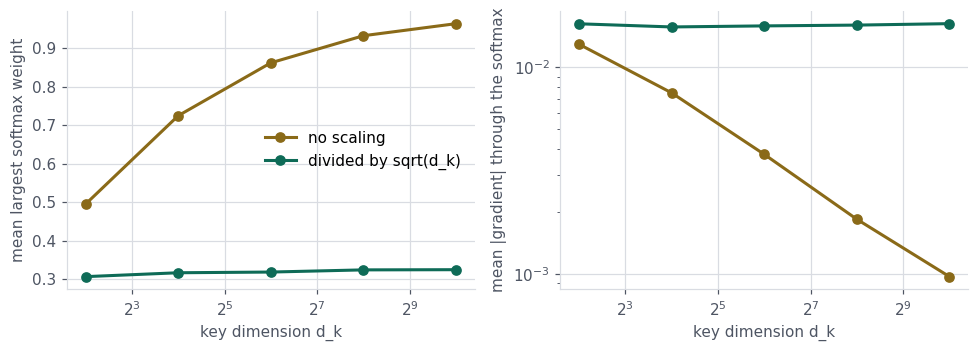

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for scaled, color, label in ((False, AMBER, "no scaling"), (True, GREEN, "divided by sqrt(d_k)")):
    sel = [r for r in rows if r[1] == scaled]
    axes[0].plot(dims, [r[3] for r in sel], color=color, lw=2, marker="o", label=label)
    axes[1].plot(dims, [r[4] for r in sel], color=color, lw=2, marker="o", label=label)
axes[0].set_xscale("log", base=2); axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[0].set_xlabel("key dimension d_k"); axes[0].set_ylabel("mean largest softmax weight")
axes[1].set_xlabel("key dimension d_k"); axes[1].set_ylabel("mean |gradient| through the softmax")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

Without scaling, the score spread grows as $\sqrt{d_k}$, the largest softmax
weight climbs toward 1 (the softmax is acting like a hard lookup), and the
gradient through it falls by more than an order of magnitude between $d_k = 4$
and $d_k = 1024$. With scaling the spread stays near 1, the largest weight stays
near 0.3 and the gradient stays flat. This is the same kind of failure as the vanishing gradients
of Module 04, caused here by saturation instead of repeated multiplication.

## 4. Distance stops mattering

Module 04's delayed-recall task: step 0 carries a class label, every later step
carries noise, and the label must be reported at the last step. In 600 updates an
LSTM with an open forget gate solved 60 steps and stayed at chance at 200.

Here the model is the smallest possible attention network. One learned query
vector looks at every step, scaled dot-product attention blends their values, and
a linear layer reads out the class. There is no recurrence.

In [8]:
def make_recall_batch(batch_size, seq_len, generator, n_classes=4, noise_dim=2):
    """Delayed recall from Module 04. Step 0 carries a class label as a one-hot vector in the first
    n_classes features; every later step is noise. The label is read out at the last step."""
    labels = torch.randint(0, n_classes, (batch_size,), generator=generator)
    x = torch.randn(batch_size, seq_len, n_classes + noise_dim, generator=generator) * 0.5
    x[:, :, :n_classes] = 0.0
    x[torch.arange(batch_size), 0, labels] = 1.0
    return x, labels

In [9]:
class AttentionReadout(nn.Module):
    """One learned query attends over all steps. Keys and values come from linear maps of the inputs."""

    def __init__(self, n_inputs=6, d=32, n_classes=4):
        super().__init__()
        self.key = nn.Linear(n_inputs, d)
        self.value = nn.Linear(n_inputs, d)
        self.query = nn.Parameter(torch.randn(1, 1, d) * 0.1)
        self.head = nn.Linear(d, n_classes)

    def forward(self, x, return_weights=False):
        q = self.query.expand(x.shape[0], -1, -1)
        out, weights = scaled_dot_product_attention(q, self.key(x), self.value(x))
        logits = self.head(out[:, 0])
        return (logits, weights) if return_weights else logits


def train_attention_recall(seq_len, seed=0, steps=600):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed + 100)
    model = AttentionReadout()
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    x_val, y_val = make_recall_batch(1000, seq_len, torch.Generator().manual_seed(999))
    for _ in range(steps):
        x, y = make_recall_batch(64, seq_len, gen)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        logits, weights = model(x_val, return_weights=True)
    return (logits.argmax(1) == y_val).float().mean().item(), weights[:, 0, 0].mean().item()

In [10]:
lengths = [30, 60, 100, 200, 400, 800]
results = {}
print(f"{'length':>7s}  accuracy for seeds 0, 1, 2   mean weight on step 0 (seed 2)")
for T in lengths:
    runs = [train_attention_recall(T, seed=s) for s in range(3)]
    results[T] = runs
    print(f"{T:7d}  {[round(a, 3) for a, _ in runs]}   {runs[-1][1]:.2f}")

 length  accuracy for seeds 0, 1, 2   mean weight on step 0 (seed 2)
     30  [1.0, 1.0, 1.0]   0.73
     60  [1.0, 1.0, 1.0]   0.72
    100  [1.0, 1.0, 1.0]   0.73
    200  [1.0, 1.0, 1.0]   0.73
    400  [1.0, 1.0, 1.0]   0.73
    800  [1.0, 1.0, 1.0]   0.74


Every length, every seed: accuracy 1.0 against a chance level of 0.25. The model
puts about 0.73 of its attention weight on step 0, which is where the label is, and
that share stays about the same whether there are 30 steps or 800. The number of
noise steps in between does not matter, because the label is one hop away from the
last step, not $T - 1$ hops.

For comparison, the open-gate LSTM from Module 04 on the same task and budget:

In [11]:
class RecallLSTM(nn.Module):
    def __init__(self, hidden=32, forget_bias=3.0):
        super().__init__()
        self.rnn = nn.LSTM(6, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 4)
        with torch.no_grad():                       # forget gate is slice [H:2H]; effective bias = sum of the two vectors
            self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(forget_bias / 2)
            self.rnn.bias_hh_l0[hidden:2 * hidden].fill_(forget_bias / 2)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])


def train_lstm_recall(seq_len, seed=0, steps=600):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed + 100)
    model = RecallLSTM()
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    x_val, y_val = make_recall_batch(1000, seq_len, torch.Generator().manual_seed(999))
    for _ in range(steps):
        x, y = make_recall_batch(64, seq_len, gen)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        return (model(x_val).argmax(1) == y_val).float().mean().item()

In [12]:
for T in (30, 60, 100, 200):
    print(f"LSTM with forget bias 3, {T:3d} steps, seed 0: accuracy {train_lstm_recall(T):.3f}")

LSTM with forget bias 3,  30 steps, seed 0: accuracy 1.000
LSTM with forget bias 3,  60 steps, seed 0: accuracy 1.000
LSTM with forget bias 3, 100 steps, seed 0: accuracy 0.252
LSTM with forget bias 3, 200 steps, seed 0: accuracy 0.251


In this run the LSTM solves 30 and 60 steps and is already at chance by 100.
A recurrent network pays for distance because the label must survive every
intermediate update. An attention read does not. That is the first of the two
limits from Module 04, the length of the path, removed.

An honest qualifier: this is one task, one seed per comparison for the LSTM, and
a fixed budget of 600 updates. The point is the direction and size of the gap, not
a claim that no LSTM could ever learn 200 steps.

## Try it

1. In section 3, change the number of keys per query from 10 to 100. Does the
   maximum weight at $d_k = 4$ change? Why?
2. In section 4, replace the learned query with a **fixed** random one (set
   `requires_grad=False`). Does the model still learn? What does that say about
   what the query is for?
3. Remove the `/ math.sqrt(d_k)` from `scaled_dot_product_attention` (pass
   `scale=False`) and retrain at length 200. With $d_k = 32$, does it still work?
   What would you expect at $d_k = 1024$?
4. In your own words: what is the difference between "attending to step 0" and
   "remembering step 0"?

## What this notebook showed

- A soft lookup is a similarity-weighted blend of values. Attention is that idea
  with learned queries, keys and values.
- Written by hand, scaled dot-product attention matches PyTorch exactly, and a
  causal mask gives exactly zero weight to the future.
- Without the $\sqrt{d_k}$ scaling, score spread grows with dimension, the softmax
  saturates and its gradient falls; with it, both stay steady.
- One attention read solves 800-step delayed recall that a gated recurrent network
  does not learn within the same budget beyond about 60 steps, because the distance
  between any two positions is one hop.